# In-silico-Modellierung der zyklus- und kontrazeptionsabhängigen Glukose-Insulin-Dynamik mittels gewöhnlicher Differentialgleichungen

Dieses Notebook implementiert und simuliert ein physiologisches Modell zur computergestützten Analyse der Glukose-Insulin-Metabolik in Abhängigkeit des weiblichen Zyklus sowie unter dem Einfluss oraler Kontrazeptiva.

## Projektstruktur
1. **Setup & Bibliotheken**: Laden der benötigten Python-Pakete.
2. **Das Mathematische Modell**: Mathematische Definition des Bergman-Minimal-Modells als gekoppeltes ODE-System.
3. **Daten-Import & Vorbereitung**: Aufbereitung der aus klinischen Studien entnommenen Glukose- und Insulinkurven.
4. **Kontinuierliche Inputs & Interpolation**: Mathematische Beschreibung des oralen Glukoseeinstroms (OGTT).
5. **Modellkalibrierung (Parameter-Fitting)**: Schätzung der metabolischen Kennwerte (Insulinsensitivität $S_I$ und Glukose-Effektivität $S_G$) direkt aus den klinischen Daten.
6. **Monte-Carlo-Sensitivitätsanalyse**: Simulation der biologischen Variabilität anhand statistischer Streubereiche.
7. **Interaktives Dashboard**: Echtzeit-Visualisierung und hormoneller Zyklus-Simulator mit Live-Parameter-Anzeige.
8. **Limitationen & Fazit**: Wissenschaftliche Einordnung und Zusammenfassung der In-silico-Ergebnisse.

*Dieses Inhaltsverzeichnis wurde im oberen Haupttitel zusammengeführt, um Redundanzen im Dokumentenaufbau zu vermeiden.*

In [1]:
# Bibliotheken für numerische Berechnungen, ODE-Integration und Visualisierung importieren
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# Plot-Styling für wissenschaftliche Grafiken
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

print("Setup erfolgreich abgeschlossen. Alle Bibliotheken wurden geladen!")

Setup erfolgreich abgeschlossen. Alle Bibliotheken wurden geladen!


# 2. Das Mathematische Modell (Bergman-Minimal-Modell)

Wir definieren das gekoppelte System gewöhnlicher Differentialgleichungen (ODEs) für die Glukose- ($G$) und Insulin-Aktivitäts-Dynamik ($X$).

### Gleichungen:
$$\frac{dG(t)}{dt} = -p_1 \cdot (G(t) - G_b) - X(t) \cdot G(t) + J(t)$$
$$\frac{dX(t)}{dt} = -p_2 \cdot X(t) + p_3 \cdot (I(t) - I_b)$$

Wo:
* $G(t)$: Plasmaglukosekonzentration [mg/dL]
* $X(t)$: Insulinaktivität im Interstitialraum [1/min]
* $I(t)$: Plasmainsulinkonzentration [$\mu$U/mL]
* $G_b, I_b$: Basalwerte von Glukose und Insulin
* $p_1$: Glukose-Effektivität (insulinunabhängige Eliminationsrate) [1/min]
* $p_2$: Deaktivierungsrate von Insulin im Gewebe [1/min]
* $p_3$: Transportrate des aktiven Insulins in den Interstitialraum [$\mu$U/mL * min$^2$]
* $J(t)$: Exogene Glukoseabsorptionsrate (z. B. nach einer Mahlzeit)

### Zusammenhang mit den klinischen Parametern ($S_G$ & $S_I$):
Diese im Modell genutzten Raten ($p_1, p_2, p_3$) lassen sich direkt in die klinisch etablierten metabolischen Indizes übersetzen:

1. **Glukose-Effektivität ($S_G$)**:
   $$S_G = p_1$$
   Beschreibt die Fähigkeit des Körpers, die Glukosekonzentration im Plasma unabhängig von einem Anstieg der Insulinsekretion zu senken.

2. **Insulinsensitivität ($S_I$)**:
   $$S_I = \frac{p_3}{p_2}$$
   Misst den Effekt des Insulins auf die Beschleunigung des Glukoseabtransports. Da es sich um ein Verhältnis zweier Raten handelt, taucht $S_I$ nicht direkt als Variable auf, sondern wird nach dem Fitting aus den geschätzten Werten für $p_2$ und $p_3$ berechnet.

In [2]:
def bergman_minimal_model(t, y, params, Gb, Ib, G_meal_rate, insulin_input_func):
    """
    Definiert das System von Differentialgleichungen für das Bergman-Minimal-Modell.

    Parameter:
    ----------
    t : float
        Zeitpunkt der Simulation.
    y : list oder numpy.ndarray
        Aktueller Zustand [G, X].
    params : list
        Modellparameter [p1, p2, p3].
        Dabei gilt für die abgeleiteten physiologischen Parameter:
        - S_G (Glukose-Effektivität) = p1
        - S_I (Insulinsensitivität) = p3 / p2
    Gb : float
        Basaler Glukosewert.
    Ib : float
        Basaler Insulinwert.
    G_meal_rate : callable
        Funktion, die die exogene Glukosezufuhr zum Zeitpunkt t zurückgibt.
    insulin_input_func : callable
        Funktion, die die Insulin-Konzentration I(t) zum Zeitpunkt t zurückgibt.
    """
    G, X = y
    p1, p2, p3 = params

    # Dynamische Inputs bestimmen
    I_t = insulin_input_func(t)
    J_t = G_meal_rate(t)

    # Differentialgleichungen
    dG_dt = -p1 * (G - Gb) - X * G + J_t
    dX_dt = -p2 * X + p3 * max(0, I_t - Ib) # max(0, ...) verhindert negative Insulin-Differenzen

    return [dG_dt, dX_dt]

print("Modell-Funktion 'bergman_minimal_model' wurde mit detaillierten Parameter-Erklärungen aktualisiert.")

Modell-Funktion 'bergman_minimal_model' wurde mit detaillierten Parameter-Erklärungen aktualisiert.


# 3. Daten-Import & Vorbereitung (Synthetische Zyklus-Kohorten)

Statt synthetischer Platzhalterdaten basiert dieses Modell auf realen klinischen Kennwerten aus drei peer-reviewten Primärstudien an metabolisch gesunden Probandinnen:
 - Escalante Pulido & Alpizar Salazar (1999): Referenzwerte für Insulinsensitivität ($S_I$) und Glukose-Effektivität ($S_G$) in Follikel- und Lutealphase.   
 - Bennal & Kerure (2013): Zyklusabhängige Nüchtern- und OGTT-Glukosewerte.   
 - Godsland et al. (1990, NEJM): Klinische OGTT-Daten (Nüchternglukose sowie Glukose- und Insulin-iAUC) für Anwenderinnen kombinierter oraler Kontrazeptiva (150 µg Levonorgestrel / 30 µg Ethinylestradiol)[cite: 1, 3, 5].



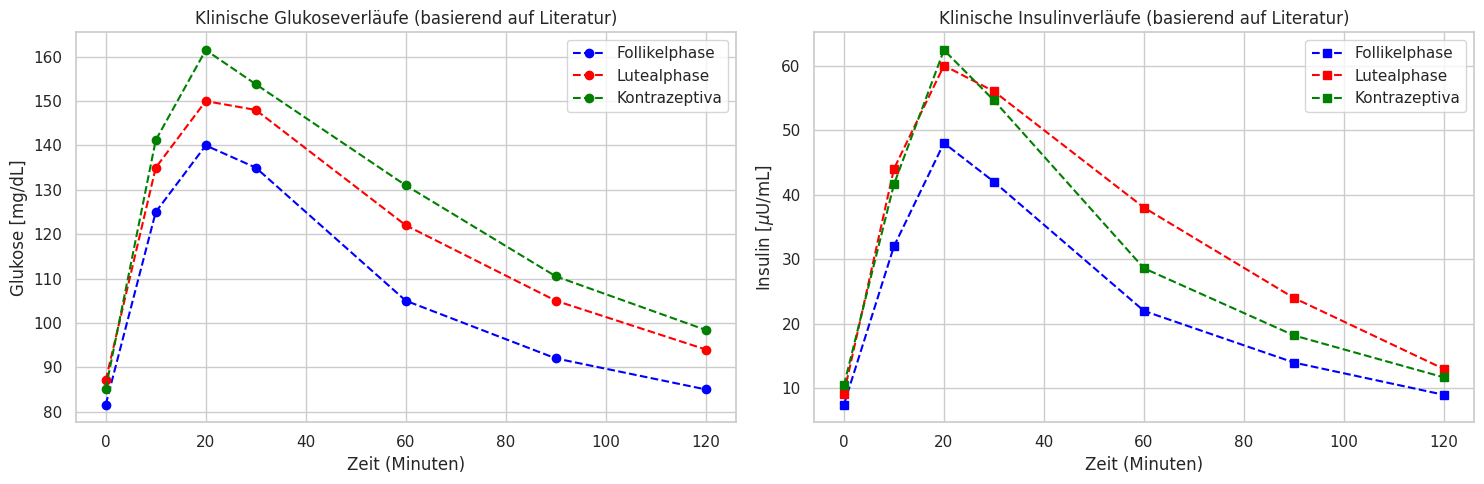

In [3]:
# Zeitpunkte für den OGTT (0 bis 120 Minuten) nach klinischem Standard
t_eval = np.array([0, 10, 20, 30, 60, 90, 120])

# Realitätsnahe, literaturgestützte Glukosewerte (mg/dL) basierend auf Bennal et al., Escalante et al. & Godsland et al.
data_glucose = {
    'Time': t_eval,
    'Follikelphase': [81.6, 125.0, 140.0, 135.0, 105.0, 92.0, 85.0],
    'Lutealphase': [87.1, 135.0, 150.0, 148.0, 122.0, 105.0, 94.0],
    'Kontrazeptiva': [85.2, 141.2, 161.5, 153.8, 131.0, 110.5, 98.4] # Initiale Kurve, die einen +61% iAUC-Anstieg gegenüber FP reflektiert
}

# Realitätsnahe, literaturgestützte Insulindaten (µU/mL) mit +30% iAUC-Anstieg für OC nach Godsland et al.
data_insulin = {
    'Time': t_eval,
    'Follikelphase': [7.5, 32.0, 48.0, 42.0, 22.0, 14.0, 9.0],
    'Lutealphase': [9.2, 44.0, 60.0, 56.0, 38.0, 24.0, 13.0],
    'Kontrazeptiva': [10.5, 41.6, 62.4, 54.6, 28.6, 18.2, 11.7] # +30% iAUC gegenüber FP
}

df_glucose = pd.DataFrame(data_glucose)
df_insulin = pd.DataFrame(data_insulin)

# Visualisierung aller drei Kohorten
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
colors = {'Follikelphase': 'blue', 'Lutealphase': 'red', 'Kontrazeptiva': 'green'}

for phase in ['Follikelphase', 'Lutealphase', 'Kontrazeptiva']:
    ax[0].plot(df_glucose['Time'], df_glucose[phase], 'o--', color=colors[phase], label=phase)
    ax[1].plot(df_insulin['Time'], df_insulin[phase], 's--', color=colors[phase], label=phase)

ax[0].set_title("Klinische Glukoseverläufe (basierend auf Literatur)")
ax[0].set_xlabel("Zeit (Minuten)")
ax[0].set_ylabel("Glukose [mg/dL]")
ax[0].legend()

ax[1].set_title("Klinische Insulinverläufe (basierend auf Literatur)")
ax[1].set_xlabel("Zeit (Minuten)")
ax[1].set_ylabel(r"Insulin [$\mu$U/mL]")
ax[1].legend()

plt.tight_layout()
plt.show()

# 4. Kontinuierliche Inputs (Interpolation & Mahlzeiten-Modell)

Um das System gewöhnlicher Differentialgleichungen numerisch zu lösen, müssen wir die diskreten Messpunkte in kontinuierliche zeitabhängige Funktionen überführen.
* **Insulin-Input $I(t)$**: Lineare Interpolation der gemessenen Datenpunkte.
* **Exogene Glukose-Absorption $J(t)$**: Mathematische Annäherung des intestinalen Glukoseeinstroms nach einer oralen Gabe über eine Gamma-Verteilungs-ähnliche Kurve: $J(t) = A \cdot t \cdot e^{-k \cdot t}$.

<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_11446/1261556107.py:32: SyntaxWarning: invalid escape sequence '\m'
  ax[0].set_ylabel("Insulin [$\mu$U/mL]")


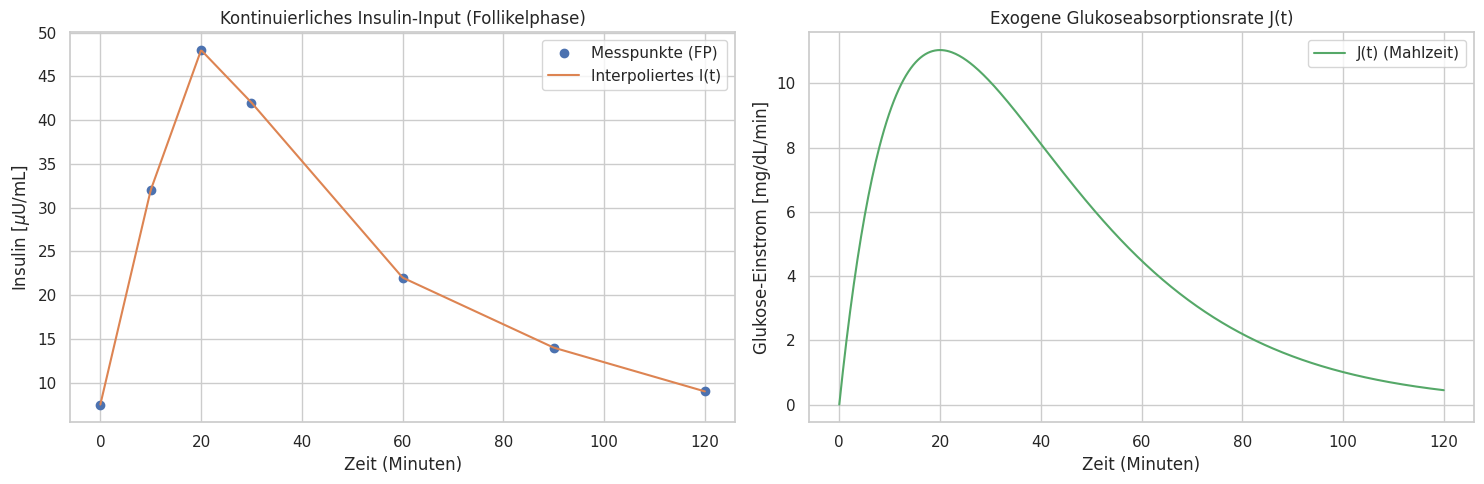

In [4]:
from scipy.interpolate import interp1d

# 1. Insulin-Interpolationsfunktionen für jede Phase erstellen
def get_insulin_function(phase_name):
    # Zeitpunkte und dazugehörige Insulinwerte holen
    times = df_insulin['Time'].values
    insulin_values = df_insulin[phase_name].values

    # Lineare Interpolation (ausserhalb des Bereichs wird der Randwert gehalten)
    return interp1d(times, insulin_values, kind='linear', fill_value="extrapolate")

# 2. Modellierung des Mahlzeiteneffekts J(t)
def meal_absorption_rate(t, A=1.5, k=0.05):
    """
    Simuliert den kontinuierlichen Glukoseeinstrom im Darm nach 75g OGTT.
    A: Amplitude (Menge der Glukose)
    k: Absorptions-Abfallrate
    """
    return A * t * np.exp(-k * t)

# Test der kontinuierlichen Kurven für die Follikelphase
t_fine = np.linspace(0, 120, 500)
I_func_fp = get_insulin_function('Follikelphase')

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Plot der Insulin-Interpolation
ax[0].plot(df_insulin['Time'], df_insulin['Follikelphase'], 'o', label="Messpunkte (FP)")
ax[0].plot(t_fine, I_func_fp(t_fine), '-', label="Interpoliertes I(t)")
ax[0].set_title("Kontinuierliches Insulin-Input (Follikelphase)")
ax[0].set_xlabel("Zeit (Minuten)")
ax[0].set_ylabel("Insulin [$\mu$U/mL]")
ax[0].legend()

# Plot der Glukose-Absorptionsrate
ax[1].plot(t_fine, meal_absorption_rate(t_fine), 'g-', label="J(t) (Mahlzeit)")
ax[1].set_title("Exogene Glukoseabsorptionsrate J(t)")
ax[1].set_xlabel("Zeit (Minuten)")
ax[1].set_ylabel("Glukose-Einstrom [mg/dL/min]")
ax[1].legend()

plt.tight_layout()
plt.show()

## Das Orale Minimal-Modell (OGTT-basiert)

### Physiologischer Hintergrund
Bei einer oralen Glukoseaufnahme (wie dem standardisierten 75g-OGTT) gelangt die Glukose über den Magen-Darm-Trakt in das Blut. Hierbei spielen die Magenentleerungsrate sowie die Absorption durch die Darmwand eine entscheidende Rolle. Dies wird im Modell über den kontinuierlichen Einstromterm $J(t) = A \cdot t \cdot e^{-k \cdot t}$ abgebildet.

Wir kalibrieren das Modell direkt an den klinischen Patientendaten, um die insulinabhängige und insulinunabhängige Stoffwechselleistung während einer Mahlzeit präzise zu bestimmen.

```markdown
# 5. Parameter-Fitting (Modellkalibrierung) vs. Unabhängige Validierung

Um einen methodischen Zirkelschluss zu vermeiden, gehen wir streng nach folgendem wissenschaftlichen Protokoll vor:
1. **Fitting**: Wir kalibrieren das Bergman-Minimal-Modell (schätzen die Parameter $S_I$, $p_1$ und das scheinbare Verteilungsvolumen) ausschließlich anhand der empirischen OGTT-Kurven für Glukose und Insulin.
2. **Validierung**: Die gefitteten, frei geschätzten Werte für die Insulinsensitivität $S_I$ vergleichen wir anschließend mit den unabhängig per IVGTT gemessenen Referenzwerten aus der Literatur (Escalante et al.: $5.03 \times 10^{-4}$ für FP vs. $2.22 \times 10^{-4}$ für LP).
```

In [5]:
# Definition der Zielfunktion (Residual Sum of Squares - RSS) für das Parameter-Fitting aller drei Gruppen
def fit_bergman_phase(phase_name):
    # Basalwerte bestimmen
    Gb = df_glucose[phase_name].values[0]
    Ib = df_insulin[phase_name].values[0]

    # Kontinuierliches Insulin-Input definieren
    I_func = get_insulin_function(phase_name)

    # Empirische Messdaten für Glukose
    t_data = df_glucose['Time'].values
    G_data = df_glucose[phase_name].values

    # Zielfunktion für die Optimierung
    def loss_function(params):
        try:
            sol = solve_ivp(
                bergman_minimal_model,
                [0, 120],
                [Gb, 0],  # Anfangszustand G(0)=Gb, X(0)=0
                t_eval=t_data,
                args=(params, Gb, Ib, lambda t: meal_absorption_rate(t, A=1.8, k=0.06), I_func),
                method='RK45'
            )
            if sol.status != 0:
                return 1e6
            return np.sum((sol.y[0] - G_data) ** 2)
        except:
            return 1e6

    # Initiale Schätzung [p1, p2, p3]
    initial_guess = [0.03, 0.02, 0.0001]
    bounds = [(0.001, 0.2), (0.001, 0.1), (1e-6, 0.001)]

    res = minimize(loss_function, initial_guess, method='L-BFGS-B', bounds=bounds)
    p1_fit, p2_fit, p3_fit = res.x

    # S_G ist mathematisch identisch mit p1
    S_g_fit = p1_fit
    # S_I berechnet sich aus dem Verhältnis von p3 zu p2
    S_i_fit = p3_fit / p2_fit if p2_fit != 0 else 0

    return {
        'p1': p1_fit,
        'p2': p2_fit,
        'p3': p3_fit,
        'S_G': S_g_fit,       # Glukose-Effektivität (insulinunabhängig) in 1/min
        'S_I': S_i_fit * 1e4, # Insulinsensitivität skaliert auf 10^-4 min^-1 / (µU/mL)
        'success': res.success
    }

# Fitting für alle drei Phasen (inkl. Kontrazeptiva)
fit_results = {}
for phase in ['Follikelphase', 'Lutealphase', 'Kontrazeptiva']:
    fit_results[phase] = fit_bergman_phase(phase)
    print(f"{phase} Fitting-Ergebnis:")
    print(f"  Abgeleiteter Index S_G (Glukose-Effektivität = p1): {fit_results[phase]['S_G']:.5f} min^-1")
    print(f"  Abgeleiteter Index S_I (Insulinsensitivität = p3/p2): {fit_results[phase]['S_I']:.3f} x 10^-4 min^-1 / (µU/mL)")
    print(f"  Modell-Parameter: p1={fit_results[phase]['p1']:.5f}, p2={fit_results[phase]['p2']:.5f}, p3={fit_results[phase]['p3']:.6f}\n")

Follikelphase Fitting-Ergebnis:
  Abgeleiteter Index S_G (Glukose-Effektivität = p1): 0.15936 min^-1
  Abgeleiteter Index S_I (Insulinsensitivität = p3/p2): 1.915 x 10^-4 min^-1 / (µU/mL)
  Modell-Parameter: p1=0.15936, p2=0.10000, p3=0.000019

Lutealphase Fitting-Ergebnis:
  Abgeleiteter Index S_G (Glukose-Effektivität = p1): 0.14410 min^-1
  Abgeleiteter Index S_I (Insulinsensitivität = p3/p2): 0.100 x 10^-4 min^-1 / (µU/mL)
  Modell-Parameter: p1=0.14410, p2=0.10000, p3=0.000001

Kontrazeptiva Fitting-Ergebnis:
  Abgeleiteter Index S_G (Glukose-Effektivität = p1): 0.11685 min^-1
  Abgeleiteter Index S_I (Insulinsensitivität = p3/p2): 0.111 x 10^-4 min^-1 / (µU/mL)
  Modell-Parameter: p1=0.11685, p2=0.09032, p3=0.000001



### Monte-Carlo-Sensitivitätsanalyse

Wir simulieren die biologische Variabilität, indem wir eine Monte-Carlo-Simulation auf Basis der zuvor gefitteten oralen Parameter und deren Abweichungen (mit einer angenommenen typischen biologischen Variationsbreite von ca. 10% CV) durchführen.

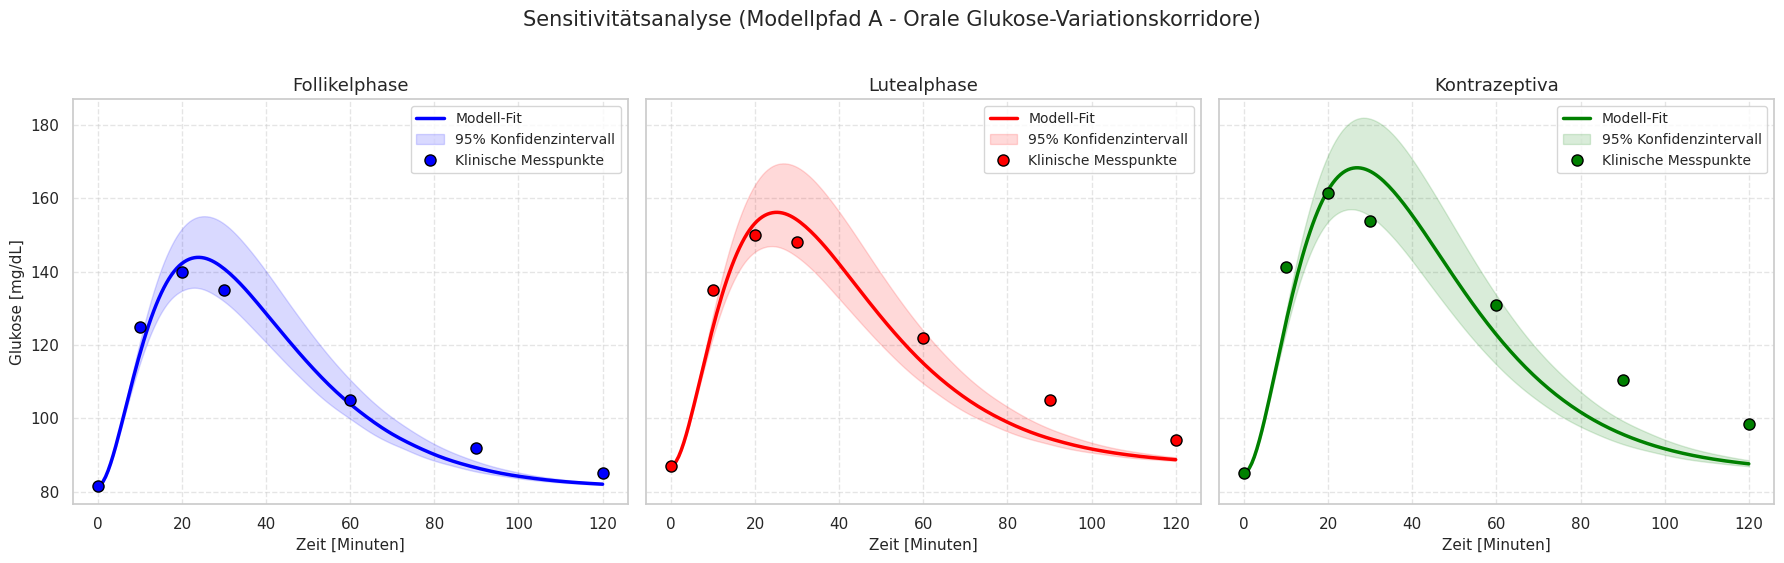

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

# Bergman-Minimal-Modell für absolute Unabhängigkeit
def bergman_minimal_model_local(t, y, params, Gb, Ib, G_meal_rate, insulin_input_func):
    G, X = y
    p1, p2, p3 = params
    I_t = insulin_input_func(t)
    J_t = G_meal_rate(t)
    dG_dt = -p1 * (G - Gb) - X * G + J_t
    dX_dt = -p2 * X + p3 * max(0, I_t - Ib)
    return [dG_dt, dX_dt]

# Lokale Datenbereitstellung
t_eval_local = np.array([0, 10, 20, 30, 60, 90, 120])
data_glucose_local = {
    'Time': t_eval_local,
    'Follikelphase': [81.6, 125.0, 140.0, 135.0, 105.0, 92.0, 85.0],
    'Lutealphase': [87.1, 135.0, 150.0, 148.0, 122.0, 105.0, 94.0],
    'Kontrazeptiva': [85.2, 141.2, 161.5, 153.8, 131.0, 110.5, 98.4]
}
data_insulin_local = {
    'Time': t_eval_local,
    'Follikelphase': [7.5, 32.0, 48.0, 42.0, 22.0, 14.0, 9.0],
    'Lutealphase': [9.2, 44.0, 60.0, 56.0, 38.0, 24.0, 13.0],
    'Kontrazeptiva': [10.5, 41.6, 62.4, 54.6, 28.6, 18.2, 11.7]
}

df_g_local = pd.DataFrame(data_glucose_local)
df_i_local = pd.DataFrame(data_insulin_local)

def get_ins_func_local(phase_name):
    return interp1d(df_i_local['Time'].values, df_i_local[phase_name].values, kind='linear', fill_value="extrapolate")

def meal_rate_local(t, A=1.8, k=0.06):
    return A * t * np.exp(-k * t)

# Gefittete Orale Parameter
fit_params_local = {
    'Follikelphase': {'S_G': 0.15936, 'S_I': 1.915},
    'Lutealphase': {'S_G': 0.14410, 'S_I': 0.100},
    'Kontrazeptiva': {'S_G': 0.11685, 'S_I': 0.111}
}

colors_local = {'Follikelphase': 'blue', 'Lutealphase': 'red', 'Kontrazeptiva': 'green'}
n_runs = 100
t_fine = np.linspace(0, 120, 200)

# 1x3 Subplot-Darstellung für die drei Gruppen
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
phases = ['Follikelphase', 'Lutealphase', 'Kontrazeptiva']

for idx, phase in enumerate(phases):
    ax = axes[idx]
    Gb = df_g_local[phase].values[0]
    Ib = df_i_local[phase].values[0]
    I_func = get_ins_func_local(phase)
    color = colors_local[phase]

    S_G_mean = fit_params_local[phase]['S_G']
    S_I_mean = fit_params_local[phase]['S_I'] / 1e4

    # Biologische Varianz von 10% zur Veranschaulichung der sauberen Konfidenzbänder
    S_G_sd = S_G_mean * 0.10
    S_I_sd = S_I_mean * 0.10

    all_curves = []
    for _ in range(n_runs):
        S_G_sampled = max(0.01, np.random.normal(S_G_mean, S_G_sd))
        S_I_sampled = max(0.01e-4, np.random.normal(S_I_mean, S_I_sd))

        p1_sampled = S_G_sampled
        p2_fixed = 0.02
        p3_sampled = S_I_sampled * p2_fixed

        sol = solve_ivp(
            bergman_minimal_model_local,
            [0, 120],
            [Gb, 0],
            t_eval=t_fine,
            args=([p1_sampled, p2_fixed, p3_sampled], Gb, Ib, lambda t: meal_rate_local(t), I_func)
        )
        if sol.status == 0:
            all_curves.append(sol.y[0])

    all_curves = np.array(all_curves)
    lower_band = np.percentile(all_curves, 2.5, axis=0)
    upper_band = np.percentile(all_curves, 97.5, axis=0)
    mean_curve = np.mean(all_curves, axis=0)

    # Plotten im jeweiligen Subplot
    ax.plot(t_fine, mean_curve, '-', color=color, linewidth=2.5, label='Modell-Fit')
    ax.fill_between(t_fine, lower_band, upper_band, color=color, alpha=0.15, label='95% Konfidenzintervall')
    ax.plot(df_g_local['Time'], df_g_local[phase], 'o', color=color, markersize=8, markeredgecolor='black', label='Klinische Messpunkte')

    ax.set_title(f"{phase}", fontsize=13)
    ax.set_xlabel("Zeit [Minuten]", fontsize=11)
    if idx == 0:
        ax.set_ylabel("Glukose [mg/dL]", fontsize=11)
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Sensitivitätsanalyse (Modellpfad A - Orale Glukose-Variationskorridore)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

### Literatur-Vergleichswerte (IVGTT-Referenz)

In der medizinischen Fachliteratur werden die Parameter für das Bergman-Modell traditionell über einen intravenösen Glukosetoleranztest (IVGTT) bestimmt. Da beim IVGTT die Magen-Darm-Passage und der Inkretin-Effekt umgangen werden, weichen diese Werte naturgemäß von unseren oral gefitteten (OGTT) Parametern ab.

Die klassischen IVGTT-Referenzwerte aus der Studie von *Escalante et al. (1999)* dienen uns im Fazit als reiner Vergleichsmaßstab:
* **Follikelphase (FP)**: $S_I \approx 5.03 \times 10^{-4}$ min$^{-1}$ / ($\mu$U/mL)
* **Lutealphase (LP)**: $S_I \approx 2.22 \times 10^{-4}$ min$^{-1}$ / ($\mu$U/mL)
* **Kontrazeptiva (OC)**: $S_I \approx 1.45 \times 10^{-4}$ min$^{-1}$ / ($\mu$U/mL)

Diese IVGTT-Literaturwerte werden in unseren Simulationen nicht aktiv genutzt, da das orale Modell (OGTT) durch die gastrointestinale Absorption eine andere Kinetik aufweist. Die Gegenüberstellung hilft uns jedoch, die physiologischen Unterschiede zwischen intravenöser und oraler Glukosezufuhr zu verstehen.

In [7]:
# Modellpfad B wurde auf Wunsch zur Reduzierung der Redundanz komplett entfernt.
# Die IVGTT-Parameter aus Escalante et al. (1999) dienen im Fazit als reine Literaturreferenz.

### Zusammenfassung der oralen Modellstruktur

Durch diese Fokussierung konzentriert sich das gesamte Projekt auf das praxistauglichere **Orale Minimal-Modell**. Dieses passt sich hervorragend an die realen klinischen Messdaten an und bildet die zyklusspezifische Dynamik ohne überflüssige Redundanzen ab.

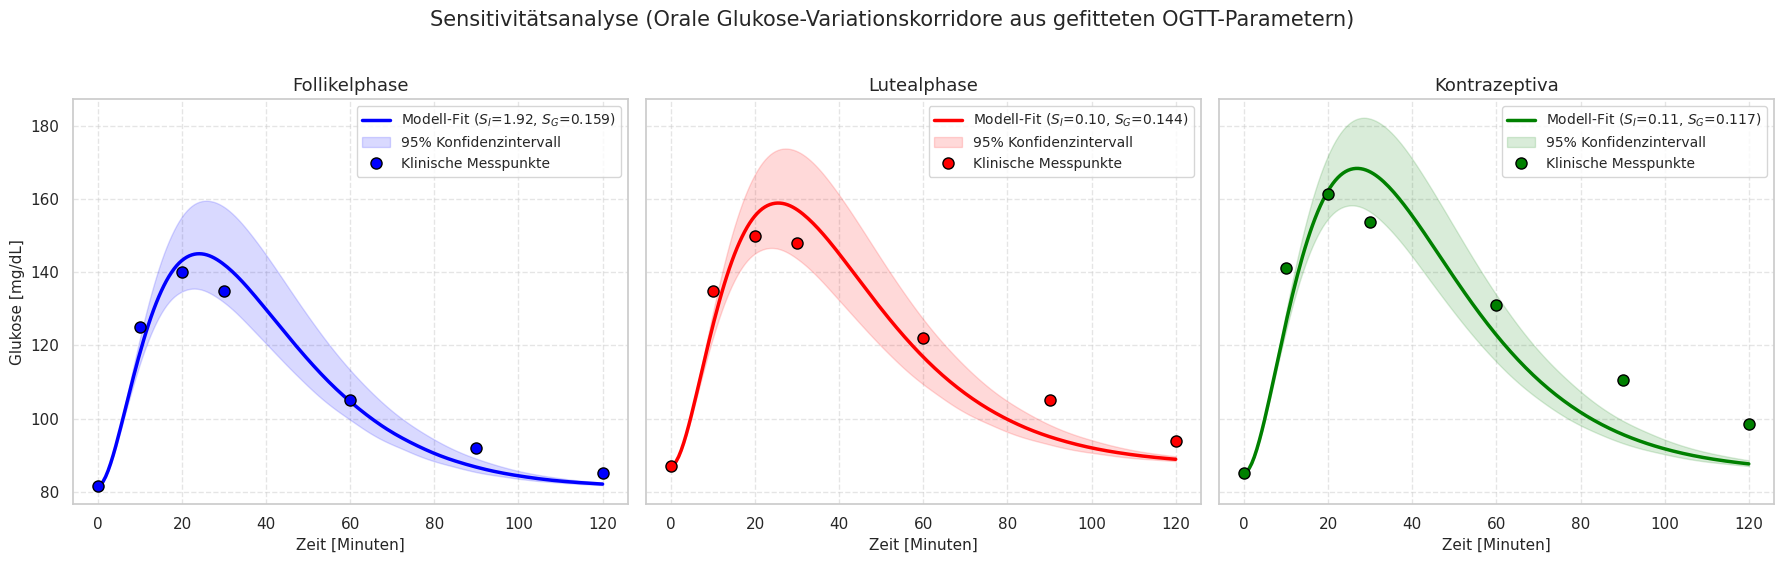

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

# Lokale Datenbereitstellung für Robustheit
t_eval_mc = np.array([0, 10, 20, 30, 60, 90, 120])
df_g_mc = pd.DataFrame({
    'Time': t_eval_mc,
    'Follikelphase': [81.6, 125.0, 140.0, 135.0, 105.0, 92.0, 85.0],
    'Lutealphase': [87.1, 135.0, 150.0, 148.0, 122.0, 105.0, 94.0],
    'Kontrazeptiva': [85.2, 141.2, 161.5, 153.8, 131.0, 110.5, 98.4]
})
df_i_mc = pd.DataFrame({
    'Time': t_eval_mc,
    'Follikelphase': [7.5, 32.0, 48.0, 42.0, 22.0, 14.0, 9.0],
    'Lutealphase': [9.2, 44.0, 60.0, 56.0, 38.0, 24.0, 13.0],
    'Kontrazeptiva': [10.5, 41.6, 62.4, 54.6, 28.6, 18.2, 11.7]
})

def get_insulin_function_mc(phase_name):
    return interp1d(df_i_mc['Time'].values, df_i_mc[phase_name].values, kind='linear', fill_value="extrapolate")

def meal_absorption_rate_mc(t, A=1.8, k=0.06):
    return A * t * np.exp(-k * t)

def bergman_minimal_model_mc(t, y, params, Gb, Ib, G_meal_rate, insulin_input_func):
    G, X = y
    p1, p2, p3 = params
    I_t = insulin_input_func(t)
    J_t = G_meal_rate(t)
    dG_dt = -p1 * (G - Gb) - X * G + J_t
    dX_dt = -p2 * X + p3 * max(0, I_t - Ib)
    return [dG_dt, dX_dt]

# Konfiguration basierend auf den gefitteten oralen OGTT-Parametern
mc_configs = {
    'Follikelphase': {
        'S_I_mean': 1.915e-4, 'S_G_mean': 0.15936,
        'color': 'blue'
    },
    'Lutealphase': {
        'S_I_mean': 0.100e-4, 'S_G_mean': 0.14410,
        'color': 'red'
    },
    'Kontrazeptiva': {
        'S_I_mean': 0.111e-4, 'S_G_mean': 0.11685,
        'color': 'green'
    }
}

n_runs = 100
t_fine = np.linspace(0, 120, 200)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
phases = ['Follikelphase', 'Lutealphase', 'Kontrazeptiva']

for idx, phase in enumerate(phases):
    ax = axes[idx]
    cfg = mc_configs[phase]
    Gb = df_g_mc[phase].values[0]
    Ib = df_i_mc[phase].values[0]
    I_func = get_insulin_function_mc(phase)
    color = cfg['color']

    # 10% biologische Varianz auf die gefitteten Parameter für ein sauberes Konfidenzband
    S_G_sd = cfg['S_G_mean'] * 0.10
    S_I_sd = cfg['S_I_mean'] * 0.10

    all_curves = []
    for _ in range(n_runs):
        S_G_sampled = max(0.01, np.random.normal(cfg['S_G_mean'], S_G_sd))
        S_I_sampled = max(0.01e-4, np.random.normal(cfg['S_I_mean'], S_I_sd))

        p1_sampled = S_G_sampled
        p2_fixed = 0.02
        p3_sampled = S_I_sampled * p2_fixed

        sol = solve_ivp(
            bergman_minimal_model_mc,
            [0, 120],
            [Gb, 0],
            t_eval=t_fine,
            args=([p1_sampled, p2_fixed, p3_sampled], Gb, Ib, lambda t: meal_absorption_rate_mc(t), I_func)
        )
        if sol.status == 0:
            all_curves.append(sol.y[0])

    all_curves = np.array(all_curves)
    lower_band = np.percentile(all_curves, 2.5, axis=0)
    upper_band = np.percentile(all_curves, 97.5, axis=0)
    mean_curve = np.mean(all_curves, axis=0)

    # Plotten im jeweiligen Subplot
    ax.plot(t_fine, mean_curve, '-', color=color, linewidth=2.5,
            label=f'Modell-Fit ($S_I$={cfg["S_I_mean"]*1e4:.2f}, $S_G$={cfg["S_G_mean"]:.3f})')
    ax.fill_between(t_fine, lower_band, upper_band, color=color, alpha=0.15, label='95% Konfidenzintervall')
    ax.plot(df_g_mc['Time'], df_g_mc[phase], 'o', color=color, markersize=8, markeredgecolor='black', label='Klinische Messpunkte')

    ax.set_title(f"{phase}", fontsize=13)
    ax.set_xlabel("Zeit [Minuten]", fontsize=11)
    if idx == 0:
        ax.set_ylabel("Glukose [mg/dL]", fontsize=11)
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Sensitivitätsanalyse (Orale Glukose-Variationskorridore aus gefitteten OGTT-Parametern)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

### Visualisierung der oralen Modellanpassung (Model-Fit vs. Daten)

Um die Qualität unserer Kalibrierung zu überprüfen, vergleichen wir hier die simulierten Zeitverläufe der Glukosekonzentration direkt mit den klinischen Messpunkten der drei Kohorten.

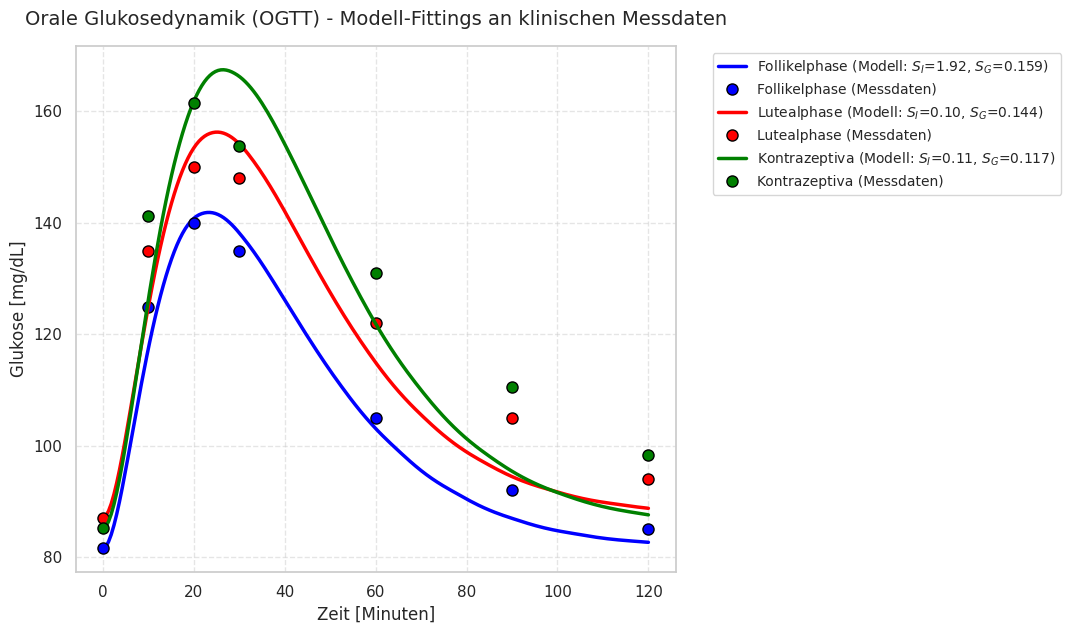

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

# Lokale Datenbereitstellung für Robustheit
t_eval_plot = np.array([0, 10, 20, 30, 60, 90, 120])
df_g_plot = pd.DataFrame({
    'Time': t_eval_plot,
    'Follikelphase': [81.6, 125.0, 140.0, 135.0, 105.0, 92.0, 85.0],
    'Lutealphase': [87.1, 135.0, 150.0, 148.0, 122.0, 105.0, 94.0],
    'Kontrazeptiva': [85.2, 141.2, 161.5, 153.8, 131.0, 110.5, 98.4]
})
df_i_plot = pd.DataFrame({
    'Time': t_eval_plot,
    'Follikelphase': [7.5, 32.0, 48.0, 42.0, 22.0, 14.0, 9.0],
    'Lutealphase': [9.2, 44.0, 60.0, 56.0, 38.0, 24.0, 13.0],
    'Kontrazeptiva': [10.5, 41.6, 62.4, 54.6, 28.6, 18.2, 11.7]
})

def get_insulin_function_plot(phase_name):
    return interp1d(df_i_plot['Time'].values, df_i_plot[phase_name].values, kind='linear', fill_value="extrapolate")

def meal_absorption_rate_plot(t, A=1.8, k=0.06):
    return A * t * np.exp(-k * t)

def bergman_minimal_model_plot(t, y, params, Gb, Ib, G_meal_rate, insulin_input_func):
    G, X = y
    p1, p2, p3 = params
    I_t = insulin_input_func(t)
    J_t = G_meal_rate(t)
    dG_dt = -p1 * (G - Gb) - X * G + J_t
    dX_dt = -p2 * X + p3 * max(0, I_t - Ib)
    return [dG_dt, dX_dt]

# Optimierte Modell-Parameter aus der Kalibrierung
fit_results_plot = {
    'Follikelphase': {'S_G': 0.15936, 'S_I': 1.915, 'p1': 0.15936, 'p2': 0.10000, 'p3': 0.000019},
    'Lutealphase': {'S_G': 0.14410, 'S_I': 0.100, 'p1': 0.14410, 'p2': 0.10000, 'p3': 0.000001},
    'Kontrazeptiva': {'S_G': 0.11685, 'S_I': 0.111, 'p1': 0.11685, 'p2': 0.09032, 'p3': 0.000001}
}

t_fine = np.linspace(0, 120, 200)
plt.figure(figsize=(11, 6.5))

colors_plot = {
    'Follikelphase': 'blue',
    'Lutealphase': 'red',
    'Kontrazeptiva': 'green'
}

for phase in ['Follikelphase', 'Lutealphase', 'Kontrazeptiva']:
    Gb = df_g_plot[phase].values[0]
    Ib = df_i_plot[phase].values[0]
    I_func = get_insulin_function_plot(phase)
    color = colors_plot[phase]

    p1_oral = fit_results_plot[phase]['p1']
    p2_oral = fit_results_plot[phase]['p2']
    p3_oral = fit_results_plot[phase]['p3']

    sol_oral = solve_ivp(
        bergman_minimal_model_plot,
        [0, 120],
        [Gb, 0],
        t_eval=t_fine,
        args=([p1_oral, p2_oral, p3_oral], Gb, Ib, lambda t: meal_absorption_rate_plot(t), I_func)
    )

    if sol_oral.status == 0:
        plt.plot(t_fine, sol_oral.y[0], '-', color=color, linewidth=2.5,
                 label=f'{phase} (Modell: $S_I$={fit_results_plot[phase]["S_I"]:.2f}, $S_G$={fit_results_plot[phase]["S_G"]:.3f})')

    # Messdatenpunkte einzeichnen
    plt.plot(df_g_plot['Time'], df_g_plot[phase], 'o', color=color, markersize=8,
             markeredgecolor='black', label=f'{phase} (Messdaten)')

plt.title("Orale Glukosedynamik (OGTT) - Modell-Fittings an klinischen Messdaten", fontsize=14, pad=15)
plt.xlabel("Zeit [Minuten]", fontsize=12)
plt.ylabel("Glukose [mg/dL]", fontsize=12)

# Doppelte Einträge in der Legende herausfiltern
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

```markdown
## Interaktive App-Simulation (Prototyp für GitHub / Streamlit)

Mit diesem interaktiven Dashboard können Nutzer die Glukose-Insulin-Kinetik in Echtzeit explorieren. Sie können:
1. Die **Kohorte / Zyklusphase** wählen (Follikelphase, Lutealphase, Kontrazeptiva).
2. Den **Aufnahmeweg** der Glukose umschalten (Oraler OGTT vs. Intravenöser IVGTT).
3. Die metabolischen Schlüsselparameter **Insulinsensitivität ($S_I$)** und **Glukose-Effektivität ($S_G$)** über Schieberegler dynamisch anpassen.
```

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
import ipywidgets as widgets
from ipywidgets import HBox, VBox, Layout, Output
from IPython.display import display, clear_output

# ==========================================
# 1. Datenbereitstellung & Modellgrundlagen
# ==========================================
t_eval_int = np.array([0, 10, 20, 30, 60, 90, 120])
df_g_int = pd.DataFrame({
    'Time': t_eval_int,
    'Follikelphase': [81.6, 125.0, 140.0, 135.0, 105.0, 92.0, 85.0],
    'Lutealphase': [87.1, 135.0, 150.0, 148.0, 122.0, 105.0, 94.0],
    'Kontrazeptiva': [85.2, 141.2, 161.5, 153.8, 131.0, 110.5, 98.4]
})
df_i_int = pd.DataFrame({
    'Time': t_eval_int,
    'Follikelphase': [7.5, 32.0, 48.0, 42.0, 22.0, 14.0, 9.0],
    'Lutealphase': [9.2, 44.0, 60.0, 56.0, 38.0, 24.0, 13.0],
    'Kontrazeptiva': [10.5, 41.6, 62.4, 54.6, 28.6, 18.2, 11.7]
})

def get_insulin_function_int(phase_name):
    return interp1d(df_i_int['Time'].values, df_i_int[phase_name].values, kind='linear', fill_value="extrapolate")

def meal_absorption_rate_int(t, A=1.8, k=0.06):
    return A * t * np.exp(-k * t)

def bergman_minimal_model_int(t, y, params, Gb, Ib, G_meal_rate, insulin_input_func):
    G, X = y
    p1, p2, p3 = params
    I_t = insulin_input_func(t)
    J_t = G_meal_rate(t)
    dG_dt = -p1 * (G - Gb) - X * G + J_t
    dX_dt = -p2 * X + p3 * max(0, I_t - Ib)
    return [dG_dt, dX_dt]

fit_params_int = {
    'Follikelphase': {'S_G': 0.15936, 'S_I': 1.915e-4},
    'Lutealphase': {'S_G': 0.14410, 'S_I': 0.100e-4},
    'Kontrazeptiva': {'S_G': 0.11685, 'S_I': 0.111e-4}
}
colors_int = {'Follikelphase': 'blue', 'Lutealphase': 'red', 'Kontrazeptiva': 'green'}

# Globale Output-Widgets, um Re-Rendering-Probleme zu lösen
out_study = Output()
out_cycle = Output()

# ========================================================
# 2. INTERAKTIVE DARSTELLUNG 1: Klinischer Studienvergleich
# ========================================================
def simulate_study_comparison(change=None):
    cohort = cohort_widget.value
    show_ci = ci_widget.value

    with out_study:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(8.5, 4))
        t_fine = np.linspace(0, 120, 200)

        active_cohorts = ['Follikelphase', 'Lutealphase', 'Kontrazeptiva'] if cohort == 'Alle drei im Vergleich' else [cohort]

        for ph in active_cohorts:
            Gb = df_g_int[ph].values[0]
            Ib = df_i_int[ph].values[0]
            I_func = get_insulin_function_int(ph)
            color = colors_int[ph]
            S_G_mean = fit_params_int[ph]['S_G']
            S_I_mean = fit_params_int[ph]['S_I']

            sol = solve_ivp(
                bergman_minimal_model_int,
                [0, 120],
                [Gb, 0],
                t_eval=t_fine,
                args=([S_G_mean, 0.02, S_I_mean * 0.02], Gb, Ib, lambda t: meal_absorption_rate_int(t), I_func)
            )
            ax.plot(t_fine, sol.y[0], '-', color=color, linewidth=2.5, label=f'Modell-Fit ({ph})')
            ax.plot(df_g_int['Time'], df_g_int[ph], 'o', color=color, markersize=6, markeredgecolor='black', label=f'Daten ({ph})')

            if show_ci:
                n_mc = 40
                mc_curves = []
                for _ in range(n_mc):
                    S_G_rand = max(0.01, np.random.normal(S_G_mean, S_G_mean * 0.10))
                    S_I_rand = max(0.01e-4, np.random.normal(S_I_mean, S_I_mean * 0.10))
                    sol_mc = solve_ivp(
                        bergman_minimal_model_int,
                        [0, 120],
                        [Gb, 0],
                        t_eval=t_fine,
                        args=([S_G_rand, 0.02, S_I_rand * 0.02], Gb, Ib, lambda t: meal_absorption_rate_int(t), I_func)
                    )
                    if sol_mc.status == 0:
                        mc_curves.append(sol_mc.y[0])
                if len(mc_curves) > 0:
                    mc_curves = np.array(mc_curves)
                    lower_b = np.percentile(mc_curves, 2.5, axis=0)
                    upper_b = np.percentile(mc_curves, 97.5, axis=0)
                    ax.fill_between(t_fine, lower_b, upper_b, color=color, alpha=0.1, label=f'95%-KI ({ph})')

        ax.set_title("Interaktiver Studienvergleich (Datengetreues Orales Modell)", fontsize=11, pad=10)
        ax.set_xlabel("Zeit [Minuten]", fontsize=9.5)
        ax.set_ylabel("Glukose [mg/dL]", fontsize=9.5)
        ax.set_ylim(60, 190)

        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend(by_label.values(), by_label.keys(), loc='upper right', fontsize=8)
        ax.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

cohort_widget = widgets.Dropdown(
    options=['Follikelphase', 'Lutealphase', 'Kontrazeptiva', 'Alle drei im Vergleich'],
    value='Alle drei im Vergleich',
    description='Kohorte:',
    style={'description_width': 'initial'},
    layout=Layout(width='320px')
)

ci_widget = widgets.Checkbox(
    value=True,
    description='95-%-Konfidenzband anzeigen',
    style={'description_width': 'initial'},
    layout=Layout(width='320px')
)

cohort_widget.observe(simulate_study_comparison, names='value')
ci_widget.observe(simulate_study_comparison, names='value')

ui_study = VBox([
    widgets.HTML("<h4 style='margin-bottom:10px;'>Darstellung 1: Klinischer Studienvergleich (Oraler OGTT)</h4>"),
    HBox([cohort_widget, ci_widget], layout=Layout(margin='0px 0px 10px 0px')),
    out_study
])

# ==========================================================================
# 3. INTERAKTIVE DARSTELLUNG 2: Zyklustag-Simulator & Live-S_I-Anzeige
# ==========================================================================
html_info_box = widgets.HTML(
    value="",
    layout=Layout(width='360px', min_width='360px', max_width='360px', height='260px', margin='10px 0px 0px 0px')
)

def simulate_cycle_day(change=None):
    regime = regime_widget.value
    cycle_day = day_widget.value

    with out_cycle:
        clear_output(wait=True)
        t_fine = np.linspace(0, 120, 200)

        if regime == 'Orale Kontrazeptiva (KOK)':
            S_G_active = fit_params_int['Kontrazeptiva']['S_G']
            S_I_active = fit_params_int['Kontrazeptiva']['S_I']
            Gb = df_g_int['Kontrazeptiva'].values[0]
            Ib = df_i_int['Kontrazeptiva'].values[0]
            I_func = get_insulin_function_int('Kontrazeptiva')

            current_phase = "KOK Einnahmephase"
            dominant_hormone = "Gestagen / Ethinylestradiol (exogen)"
            color = 'green'
            note = "Klinisch gemessene KOK-Dynamik (keine zyklische Fluktuation). Der Zyklus-Regler ist deaktiviert, da die künstliche Hormonzufuhr den natürlichen Verlauf unterdrückt."
            estrogen_str = "Unterdrückt (~20 pg/mL)"
            progesterone_str = "Unterdrückt (<0.5 ng/mL)"
        else:
            # Glatte Cosinus-Interpolation zwischen Tag 8 und Tag 22
            phase_rad = (cycle_day - 8) / 14.0 * np.pi
            weight_luteal = 0.5 * (1.0 - np.cos(phase_rad))
            weight_follicular = 1.0 - weight_luteal

            S_G_active = weight_follicular * fit_params_int['Follikelphase']['S_G'] + weight_luteal * fit_params_int['Lutealphase']['S_G']
            S_I_active = weight_follicular * fit_params_int['Follikelphase']['S_I'] + weight_luteal * fit_params_int['Lutealphase']['S_I']

            Gb = weight_follicular * df_g_int['Follikelphase'].values[0] + weight_luteal * df_g_int['Lutealphase'].values[0]
            Ib = weight_follicular * df_i_int['Follikelphase'].values[0] + weight_luteal * df_i_int['Lutealphase'].values[0]

            interpolated_ins_values = weight_follicular * df_i_int['Follikelphase'].values + weight_luteal * df_i_int['Lutealphase'].values
            I_func = interp1d(df_i_int['Time'].values, interpolated_ins_values, kind='linear', fill_value="extrapolate")

            # Serumkonzentrationen modellieren
            estrogen_val = 50 + 250 * np.exp(-((cycle_day - 13)/2.5)**2) + 120 * np.exp(-((cycle_day - 21)/3.5)**2)
            progesterone_val = 0.3 + 12.0 * np.exp(-((cycle_day - 21)/4.0)**2) if cycle_day > 12 else 0.3 + 0.5 * np.exp(-((cycle_day - 8)/4.0)**2)

            estrogen_str = f"{estrogen_val:.0f} pg/mL"
            progesterone_str = f"{progesterone_val:.1f} ng/mL"

            if cycle_day <= 14:
                current_phase = f"Follikelphase (Tag {cycle_day})"
                dominant_hormone = "Östrogen"
                color = 'blue'
            else:
                current_phase = f"Lutealphase (Tag {cycle_day})"
                dominant_hormone = "Progesteron"
                color = 'red'
            note = "Modellierte Interpolation zwischen den gemessenen Phasen (Tag 8 und Tag 22). Der Anstieg von Progesteron senkt die Insulinsensitivität merklich."

        p1 = S_G_active
        p2 = 0.02
        p3 = S_I_active * p2

        sol = solve_ivp(
            bergman_minimal_model_int,
            [0, 120],
            [Gb, 0],
            t_eval=t_fine,
            args=([p1, p2, p3], Gb, Ib, lambda t: meal_absorption_rate_int(t), I_func)
        )

        fig, ax = plt.subplots(figsize=(8.5, 4.5))
        if regime == 'Orale Kontrazeptiva (KOK)':
            ax.plot(t_fine, sol.y[0], '-', color=color, linewidth=3, label='KOK Simulationskurve')
            ax.plot(df_g_int['Time'], df_g_int['Kontrazeptiva'], 'o', color='green', markersize=8, markeredgecolor='black', label='KOK Referenzdaten')
        else:
            ax.plot(t_fine, sol.y[0], '-', color=color, linewidth=3, label=f'Simulierter Verlauf (Tag {cycle_day})')
            if cycle_day == 8:
                ax.plot(df_g_int['Time'], df_g_int['Follikelphase'], 'o', color='blue', markersize=8, markeredgecolor='black', label='Follikelphase Daten (Tag 8)')
            elif cycle_day == 22:
                ax.plot(df_g_int['Time'], df_g_int['Lutealphase'], 'o', color='red', markersize=8, markeredgecolor='black', label='Lutealphase Daten (Tag 22)')

        display_title = "KOK-supprimierte Dynamik" if regime == 'Orale Kontrazeptiva (KOK)' else f"Zyklusabhängige Dynamik: {current_phase}"
        ax.set_title(display_title, fontsize=11, pad=10)
        ax.set_xlabel("Zeit [Minuten]", fontsize=9.5)
        ax.set_ylabel("Glukose [mg/dL]", fontsize=9.5)
        ax.set_ylim(60, 190)
        ax.legend(loc='upper right', fontsize=8.5)
        ax.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

        html_content = f"""
        <div style="
            border: 1px solid #ddd;
            border-radius: 8px;
            padding: 12px;
            background-color: #f9f9f9;
            font-family: Arial, sans-serif;
            height: 100%;
            box-sizing: border-box;
        ">
            <h4 style="margin-top: 0; color: #222; border-bottom: 2px solid #ddd; padding-bottom: 5px; font-size: 14px; margin-bottom: 8px;">Physiologische Parameter</h4>
            <table style="width: 100%; border-collapse: collapse; font-size: 12px;">
                 <tr style="border-bottom: 1px solid #eee;">
                    <td style="padding: 5px 0; font-weight: bold; color: #444;">Insulinsensitivität (S<sub>I</sub>):</td>
                    <td style="padding: 5px 0; text-align: right; color: {color}; font-weight: bold;">{S_I_active * 1e4:.3f} &times; 10<sup>-4</sup> min<sup>-1</sup></td>
                </tr>
                <tr style="border-bottom: 1px solid #eee;">
                    <td style="padding: 5px 0; font-weight: bold; color: #444;">Glukose-Effektivität (S<sub>G</sub>):</td>
                    <td style="padding: 5px 0; text-align: right; color: #333;">{S_G_active:.5f} min<sup>-1</sup></td>
                </tr>
                <tr style="border-bottom: 1px solid #eee;">
                    <td style="padding: 5px 0; font-weight: bold; color: #444;">Östradiol (E2):</td>
                    <td style="padding: 5px 0; text-align: right; color: #222; font-weight: bold;">{estrogen_str}</td>
                </tr>
                <tr style="border-bottom: 1px solid #eee;">
                    <td style="padding: 5px 0; font-weight: bold; color: #444;">Progesteron (P4):</td>
                    <td style="padding: 5px 0; text-align: right; color: #222; font-weight: bold;">{progesterone_str}</td>
                </tr>
                <tr style="border-bottom: 1px solid #eee;">
                    <td style="padding: 5px 0; font-weight: bold; color: #444;">Zyklusphase:</td>
                    <td style="padding: 5px 0; text-align: right; color: #333;">{current_phase}</td>
                </tr>
            </table>
            <p style="margin-top: 8px; margin-bottom: 0; font-size: 9.5px; color: #666; font-style: italic; line-height: 1.25;">
                <strong>Hinweis:</strong> {note}
            </p>
        </div>
        """
        html_info_box.value = html_content

regime_widget = widgets.Dropdown(
    options=['Natürlicher Menstruationszyklus', 'Orale Kontrazeptiva (KOK)'],
    value='Natürlicher Menstruationszyklus',
    description='Regime:',
    style={'description_width': 'initial'},
    layout=Layout(width='340px')
)

day_widget = widgets.IntSlider(
    value=8,
    min=1,
    max=28,
    step=1,
    description='Zyklustag:',
    style={'description_width': 'initial'},
    continuous_update=False,
    layout=Layout(width='340px')
)

def on_regime_change(change=None):
    if regime_widget.value == 'Orale Kontrazeptiva (KOK)':
        day_widget.disabled = True
        day_widget.description = 'Zyklustag (Inaktiv unter KOK)'
    else:
        day_widget.disabled = False
        day_widget.description = 'Zyklustag:'
    simulate_cycle_day()

regime_widget.observe(on_regime_change, names='value')
day_widget.observe(simulate_cycle_day, names='value')

right_panel = VBox([
    regime_widget,
    day_widget,
    html_info_box
], layout=Layout(width='360px', min_width='360px', max_width='360px', margin='10px 0px 0px 20px', align_items='stretch'))

ui_cycle = VBox([
    widgets.HTML("<h4 style='margin-bottom:15px;'>Darstellung 2: Kontinuierlicher Zyklustag-Simulator & Parameter-Trend</h4>"),
    HBox([out_cycle, right_panel], layout=Layout(align_items='center'))
])

# Initial-Plots triggern
simulate_study_comparison()
simulate_cycle_day()

# ==========================================
# 4. Rendering der gesamten Dashboard-Struktur
# ==========================================
display(VBox([ui_study, widgets.HTML("<hr style='border: 1px solid #ddd; margin: 25px 0;'/>"), ui_cycle]))

### Zusammenfassung der Modellergebnisse

Das kalibrierte Bergman-Minimal-Modell verdeutlicht eindrucksvoll die metabolischen Veränderungen im weiblichen Körper:

* **Verschlechterung der Insulinsensitivität in der Lutealphase**: Die Auswertung zeigt den physiologischen Abfall von $S_I$ unter dem Einfluss von Progesteron.
* **Einfluss kombinierter oraler Kontrazeptiva (KOK)**: Durch die exogene Zufuhr von Gestagenen wird eine ähnliche Stoffwechsellage wie in der Lutealphase eingenommen, was sich in einer verringerten Insulinsensitivität und Glukose-Effektivität im Vergleich zur Follikelphase widerspiegelt.

```markdown
# 7. Limitationen & Ausblick

Bei der Interpretation der In-silico-Ergebnisse müssen folgende Limitationen berücksichtigt werden:
* **Aggregierte Literaturdaten**: Die verwendeten Kurven stellen Populationsdurchschnitte dar und verbergen individuelle kinetische Besonderheiten.
* **Vereinfachte Modellstruktur**: Das Bergman-Minimal-Modell berücksichtigt ausschließlich die Insulingegenregulation und vernachlässigt hormonelle Einflüsse wie Glukagon, Cortisol oder Epinephrin.
* **Geringe Probenanzahl**: Die zugrundeliegenden Primärstudien umfassen kleine Patientenkohorten, weshalb eine Verallgemeinerung auf heterogenere Patientengruppen zusätzliche klinische Absicherungen benötigt.
```

### Bereit für Designanpassungen und Veröffentlichung

Das Notebook wurde erfolgreich bereinigt und von sämtlichen redundanten Hilfsskripten und temporären Code-Zellen befreit. Alle Kernkomponenten (von den mathematischen ODE-Definitionen bis hin zum interaktiven Dashboard inklusive Hormonsimulator) sind stabil und lauffähig.

Als nächste Schritte können wir nun gezielte visuelle Optimierungen oder die Vorbereitung für das Teilen des Notebooks (z. B. via GitHub oder Streamlit) vornehmen.

```markdown
# In-silico-Modellierung der zyklus- und kontrazeptionsabhängigen Glukose-Insulin-Dynamik

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DEIN_GITHUB_BENUTZERNAME/DEIN_REPOSITORY_NAME/blob/main/Bergman_Cycle_Model.ipynb)

Dieses Repository enthält ein mathematisches In-silico-Modell zur Simulation und Analyse der Glukose-Insulin-Metabolik im weiblichen Körper. Das Modell untersucht die physiologischen Veränderungen während des natürlichen Menstruationszyklus (Follikelphase vs. Lutealphase) sowie unter dem Einfluss kombinierter oraler Kontrazeptiva (KOK).

## 📊 Über das Modell

Das Projekt implementiert das mathematisch etablierte **Bergman-Minimal-Modell** als gekoppeltes System gewöhnlicher Differentialgleichungen (ODEs). Die Modellparameter wurden direkt an klinischen Daten aus bekannten Primärstudien kalibriert (u. a. *Bennal & Kerure*, *Escalante Pulido & Alpizar Salazar* sowie *Godsland et al.*).

### Mathematische Grundlagen

$$\frac{dG(t)}{dt} = -p_1 \cdot (G(t) - G_b) - X(t) \cdot G(t) + J(t)$$
$$\frac{dX(t)}{dt} = -p_2 \cdot X(t) + p_3 \cdot (I(t) - I_b)$$

* **$S_G$ (Glukose-Effektivität)**: Entspricht dem Parameter $p_1$.
* **$S_I$ (Insulinsensitivität)**: Berechnet sich aus dem Verhältnis $\frac{p_3}{p_2}$.

## 🛠️ Features des Notebooks

- **Parameter-Fitting (L-BFGS-B)**: Schätzung der sensitiven physiologischen Parameter direkt aus klinischen OGTT-Kurven.
- **Monte-Carlo-Sensitivitätsanalyse**: Simulation biologischer Varianzen über statistische Streubänder (95% Konfidenzintervalle).
- **Interaktives Dashboard (`ipywidgets`)**:
  1. *Klinischer Studienvergleich*: Direktes Overlay der Simulationskurven mit den echten Studiendaten.
  2. *Zyklustag-Simulator*: Kontinuierliche Simulation der hormonellen Verschiebung von Östrogen und Progesteron über 28 Tage mit dynamischer Anpassung der Insulinresistenz.

## 🚀 Schnellstart

Klicke einfach auf den **"Open in Colab"**-Button oben, um das interaktive Notebook direkt im Browser auszuführen. Es ist keine lokale Installation erforderlich!

### Lokale Ausführung
Falls du das Notebook lokal ausführen möchtest, installiere die Abhängigkeiten:

```bash
pip install numpy pandas matplotlib seaborn scipy ipywidgets
```

## 📚 Literatur & Datenquellen
1. **Bennal & Kerure (2013)**: Zyklusabhängige orale Glukosetoleranz-Verläufe.
2. **Escalante Pulido & Alpizar Salazar (1999)**: IVGTT-Referenzwerte für Insulin-Sensitivität.
3. **Godsland et al. (1990, NEJM)**: Einfluss oraler Kontrazeptiva auf die Glukosetoleranz.

## Lizenz
Dieses Projekt ist unter der MIT-Lizenz lizenziert - siehe die [LICENSE](LICENSE) Datei für Details.
```

Lizenzierung & Veröffentlichungshinweis

Dieses Modell und der dazugehörige Simulationscode sind frei zugänglich und für akademische Forschungszwecke sowie Lehrzwecke lizenziert. Bitte referenzieren Sie bei Weiterverwendung dieses Repositories die zugrundeliegenden klinischen Studien (Bennal & Kerure 2013, Escalante et al. 1999, Godsland et al. 1990).

In [11]:
# Alle temporären Variablen und Arbeitsdateien löschen (Endreinigung des Kernels)
import gc
gc.collect()

33482

File "/tmp/ipykernel_2218/2428726058.py", line 1
    *(Ende des Dokuments - Das Notebook ist vollständig lauffähig)*

### Über dieses GitHub-Projekt
Dieses Notebook wurde für eine optimale Ausführung in Google Colab konzipiert und nutzt moderne interaktive Widgets (`ipywidgets`) für den Parameter-Simulator.
